# Stage 1: High vs. low engagement — classification and the evaluation framework

**Question.** Once a post's reach is accounted for, which content features (format, ICP segment, content pillar,
timing) separate high-engaging posts from low-engaging ones? And how much of what notebook 02 found survives a
stricter evaluation (multiple-testing correction, robust/clustered SEs, effect sizes, CV spread)?

**What this notebook is.** Like notebook 02, it presents committed runs and refits nothing. Every number comes from
a run folder under `outputs/runs/`, produced by `python -m modeling.run_classification`,
`python -m modeling.run_regression` and `python -m modeling.run_evaluation` (code in `modeling/`). The provenance
cell shows which commit and master file produced each run. A running log of every result, with its run and
commit, is in `FINDINGS.md`.

**Label.** A post is **high** if its engagement rate is above what its reach alone predicts on its platform: the
median of a median-regression **spline** of rate on log2 impressions, fit per platform on training posts only
(`reach_spline`, section 2). This keeps reach from deciding the label, so the models have to find content effects.

## 1. Setup and provenance

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

REPO = Path("..").resolve()
sys.path.insert(0, str(REPO))
from modeling.features import file_sha256, load_config  # noqa: E402

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

RUNS = {   # the committed runs this notebook reports
    "classification, reach_spline label (main)": REPO / "outputs/runs/2026-11-03_eval_label_reach_spline",
    "classification, straight-line reach label": REPO / "outputs/runs/2026-11-03_eval_classification",
    "classification, above-median label": REPO / "outputs/runs/2026-11-03_eval_label_above_median",
    "classification, top-third label": REPO / "outputs/runs/2026-11-03_eval_label_top_tercile",
    "regression (eval framework items 1–2)": REPO / "outputs/runs/2026-11-03_eval_regression",
    "evaluation framework (items 3–7)": REPO / "outputs/runs/2026-11-04_eval_framework",
}
CLS = RUNS["classification, reach_spline label (main)"]
LINE = RUNS["classification, straight-line reach label"]
REG = RUNS["regression (eval framework items 1–2)"]
EV = RUNS["evaluation framework (items 3–7)"]
LABEL_RUNS = {"reach spline (main)": CLS, "reach line": LINE,
              "above median": RUNS["classification, above-median label"],
              "top third": RUNS["classification, top-third label"]}
CONFIG = load_config()
current_sha = file_sha256(REPO / CONFIG["master"])

prov = []
for name, path in RUNS.items():
    info = json.loads((path / "run_info.json").read_text())
    prov.append({"run": name, "folder": path.name, "label": info.get("label", "–"),
                 "commit": info["git"]["commit"][:7], "clean_commit": not info["git"]["uncommitted_changes"],
                 "master_matches_current": info["master_sha256"] == current_sha, "seed": info["seed"]})
prov = pd.DataFrame(prov)
display(prov)
assert prov["master_matches_current"].all(), "A run was made on a different master file than the current one."
assert CONFIG["classification"]["main_label"] == "reach_spline"

,run,folder,label,commit,clean_commit,master_matches_current,seed
0,"classification, reach_spline label (main)",2026-11-03_eval_label_reach_spline,reach_spline,593b567,True,True,26
1,"classification, straight-line reach label",2026-11-03_eval_classification,reach_adjusted,7622674,True,True,26
2,"classification, above-median label",2026-11-03_eval_label_above_median,above_median,7622674,True,True,26
3,"classification, top-third label",2026-11-03_eval_label_top_tercile,top_tercile,7622674,True,True,26
4,regression (eval framework items 1–2),2026-11-03_eval_regression,–,7622674,True,True,26
5,evaluation framework (items 3–7),2026-11-04_eval_framework,–,50d578b,True,True,26


In [2]:
def fig(run, name, width=1100):
    display(Image(filename=str(run / "figures" / name), width=width))


def read(run, name):
    return pd.read_csv(run / name)


def show(df, caption=None, precision=2):
    s = df.style.format(precision=precision, na_rep="–").hide(axis="index")
    display(s.set_caption(caption) if caption else s)


PLATFORMS = ["Facebook", "Instagram", "LinkedIn", "pooled"]
LABEL = {"log2_impressions": "Reach: impressions doubled", "WEEKEND": "Timing: weekend",
         "AFTER_11": "Timing: posted 11am or later", "BOOSTED": "LinkedIn: also paid-boosted",
         "IN_EXPERIMENT_PERIOD": "Period: Q2–Q3 experiment"}
lab = lambda f: LABEL.get(f, f)

## 2. The label: high = above the reach-expected rate
Shares of "high" posts per platform under each label. The reach labels cut at the median residual, so about half
the posts are high; the top-third label makes a third high.

In [3]:
ls = read(CLS, "label_summary.csv")
display(ls.pivot(index="label", columns="platform", values="share_high")
        .reindex(["reach_spline", "reach_adjusted", "above_median", "top_tercile"]).rename_axis("share high"))
display(read(CLS, "label_rules.csv").rename(columns={"knots_impressions": "spline knots (impressions)"}))

platform,Facebook,Instagram,LinkedIn
share high,,,
reach_spline,0.472,0.469,0.474
reach_adjusted,0.496,0.477,0.496
above_median,0.496,0.500,0.496
top_tercile,0.325,0.300,0.336


,rule,platform,spline knots (impressions),residual_threshold
0,reach_spline,Facebook,1.0 13.7 22.0 637.0,-0.000
1,reach_spline,Instagram,5.0 19.0 29.0 1415.0,0.000
2,reach_spline,LinkedIn,3.0 153.0 343.7 5752.0,-0.000


**Why a spline and not a straight line.** The first reach-adjusted label subtracted a straight line in log2
impressions. A random forest (the only model that can use curved patterns) still ranked **reach** as its most
useful group on Facebook, Instagram and pooled under that label: the curve the line missed stayed in the label.
The spline removes most of it. Below: how much held-out AUC the forest loses when reach is shuffled.

In [4]:
rows = []
for name, run in [("line", LINE), ("spline (4 knots)", CLS)]:
    f = read(run, "importance_forest.csv").query("level == 'group' and unit == 'Reach (impressions)'")
    rows.append(f.set_index("platform")["auc_drop_mean"].rename(name))
display(pd.concat(rows, axis=1).reindex(PLATFORMS).T.rename_axis("forest AUC drop, reach shuffled"))

platform,Facebook,Instagram,LinkedIn,pooled
"forest AUC drop, reach shuffled",,,,
line,0.116,0.093,-0.005,0.074
spline (4 knots),0.059,0.013,0.006,0.032


Knot sensitivity (3 and 5 knots, scratchpad trial runs, not committed; see `FINDINGS.md`, C5): reach importance
falls with more knots (Facebook 0.08 / 0.06 / 0.03; Instagram 0.01 at every count). LinkedIn, pooled Link /
Document / Carousel effects hold at 3, 4 and 5 knots; Instagram content effects hold at 3 and 4 knots only.

## 3. How well can high vs. low be predicted?
Held-out AUC on the same 50 CV splits (5-fold × 10 repeats) for every model. The **base rate** model predicts the
training share for every post (AUC 0.50). The table gives mean ± SD across splits (evaluation item 6).

platform,Facebook,Instagram,LinkedIn,pooled
"held-out AUC, mean ± SD",,,,
base rate (reference),0.50 ± 0.00,0.50 ± 0.00,0.50 ± 0.00,0.50 ± 0.00
Logistic,0.59 ± 0.10,0.65 ± 0.10,0.64 ± 0.11,0.60 ± 0.05
Decision tree,0.52 ± 0.10,0.61 ± 0.09,0.58 ± 0.09,0.54 ± 0.04
Ridge logistic,0.60 ± 0.10,0.66 ± 0.11,0.66 ± 0.10,0.60 ± 0.05
Lasso logistic,0.50 ± 0.04,0.59 ± 0.11,0.61 ± 0.10,0.56 ± 0.05
Elastic net logistic,0.51 ± 0.05,0.59 ± 0.10,0.63 ± 0.09,0.57 ± 0.05
Random forest,0.64 ± 0.11,0.67 ± 0.10,0.65 ± 0.08,0.64 ± 0.05


platform,Facebook,Instagram,LinkedIn,pooled
balanced accuracy,,,,
base rate (reference),0.500,0.500,0.500,0.500
Logistic,0.560,0.616,0.607,0.571
Decision tree,0.512,0.580,0.546,0.515
Ridge logistic,0.514,0.589,0.612,0.555
Lasso logistic,0.487,0.556,0.565,0.526
Elastic net logistic,0.506,0.558,0.572,0.538
Random forest,0.564,0.623,0.608,0.596


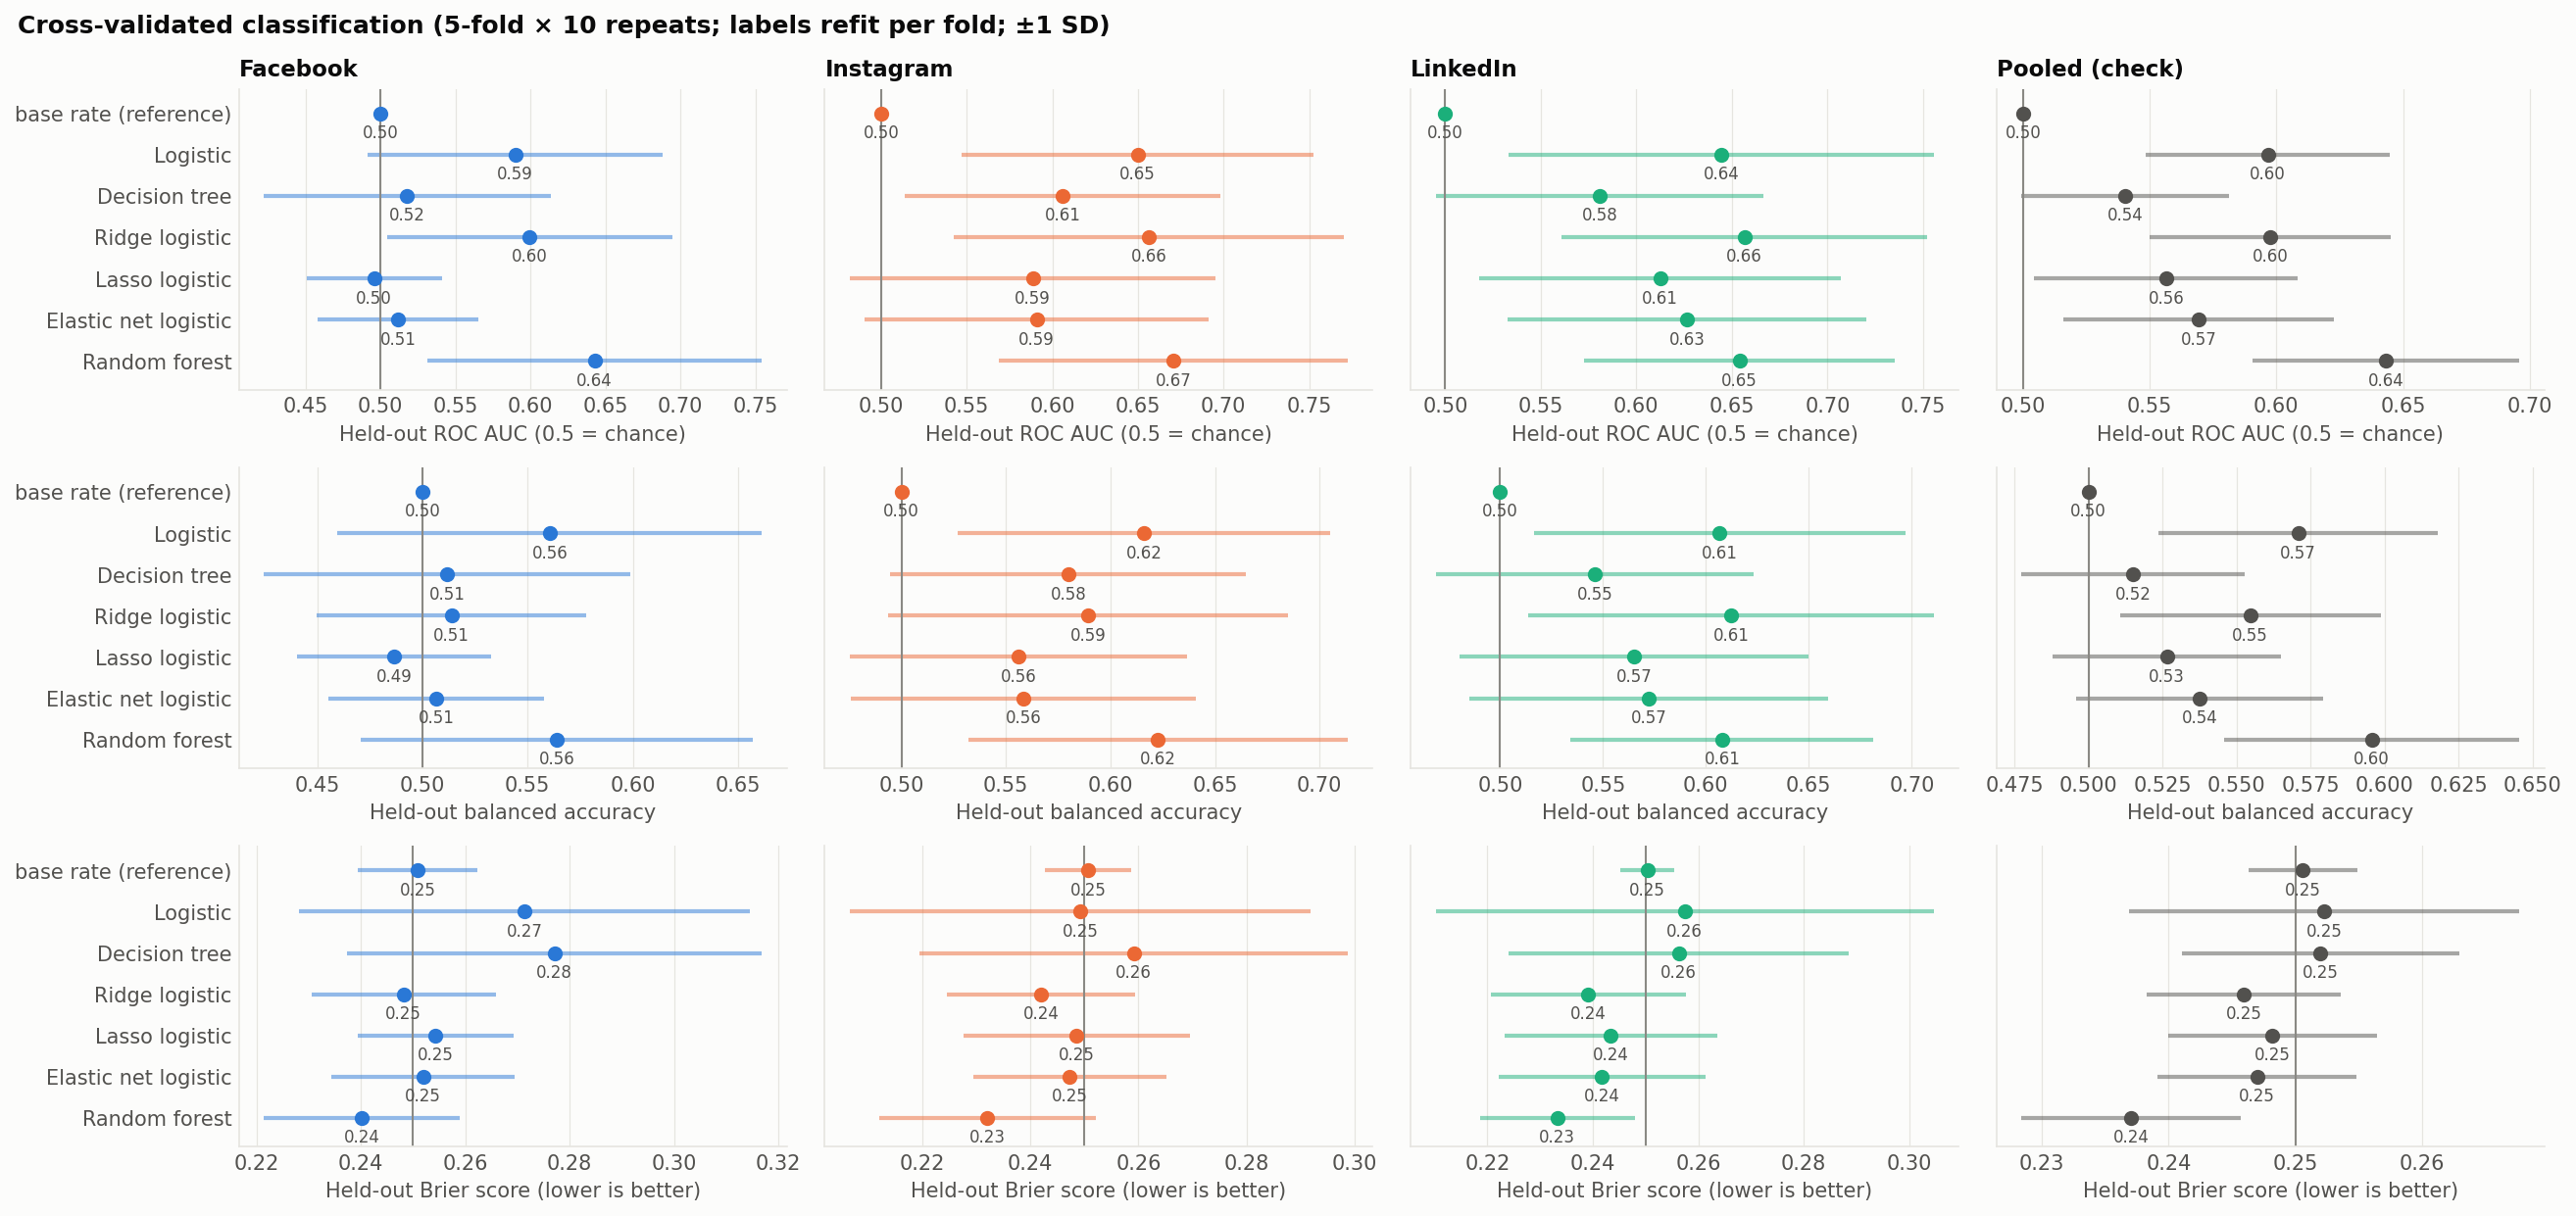

In [5]:
cms = read(EV, "cv_mean_sd.csv")
order = ["base rate (reference)", "Logistic", "Decision tree", "Ridge logistic", "Lasso logistic",
         "Elastic net logistic", "Random forest"]
auc = cms.query("task == 'classification' and metric == 'auc'")
display(auc.pivot(index="model", columns="platform", values="report").reindex(order)[PLATFORMS]
        .rename_axis("held-out AUC, mean ± SD"))
bal = read(CLS, "cv_summary.csv")
display(bal.pivot(index="model", columns="platform", values="balanced_accuracy_mean").reindex(order)[PLATFORMS]
        .rename_axis("balanced accuracy"))
fig(CLS, "cv_performance.png")

**Reading it**
- **Every platform now has some signal** (best AUC 0.64–0.67), modest but above 0.50. Linear models gained once
  reach was out of the label (Instagram ridge 0.57 → 0.66; Facebook 0.55 → 0.60).
- **SDs across splits are about 0.10 per platform**, so AUC differences under ~0.05 between models are not
  meaningful. The forest is not reliably better than ridge anywhere.
- **LinkedIn is the same under every label** (ridge ≈ 0.66): its signal is format, and it is additive.
- Precision / recall / F1 at a 0.5 cut are near 0 for lasso / elastic net when they predict the base rate for every
  post; read AUC and balanced accuracy instead.

## 4. Which features push a post toward "high"?
### 4.1 Logistic regression effects
Odds ratios with 95% CIs (plain logit, robust SEs). Odds ratio > 1 = more likely high. Formats are compared with
Image, pillars with Thought Leadership.

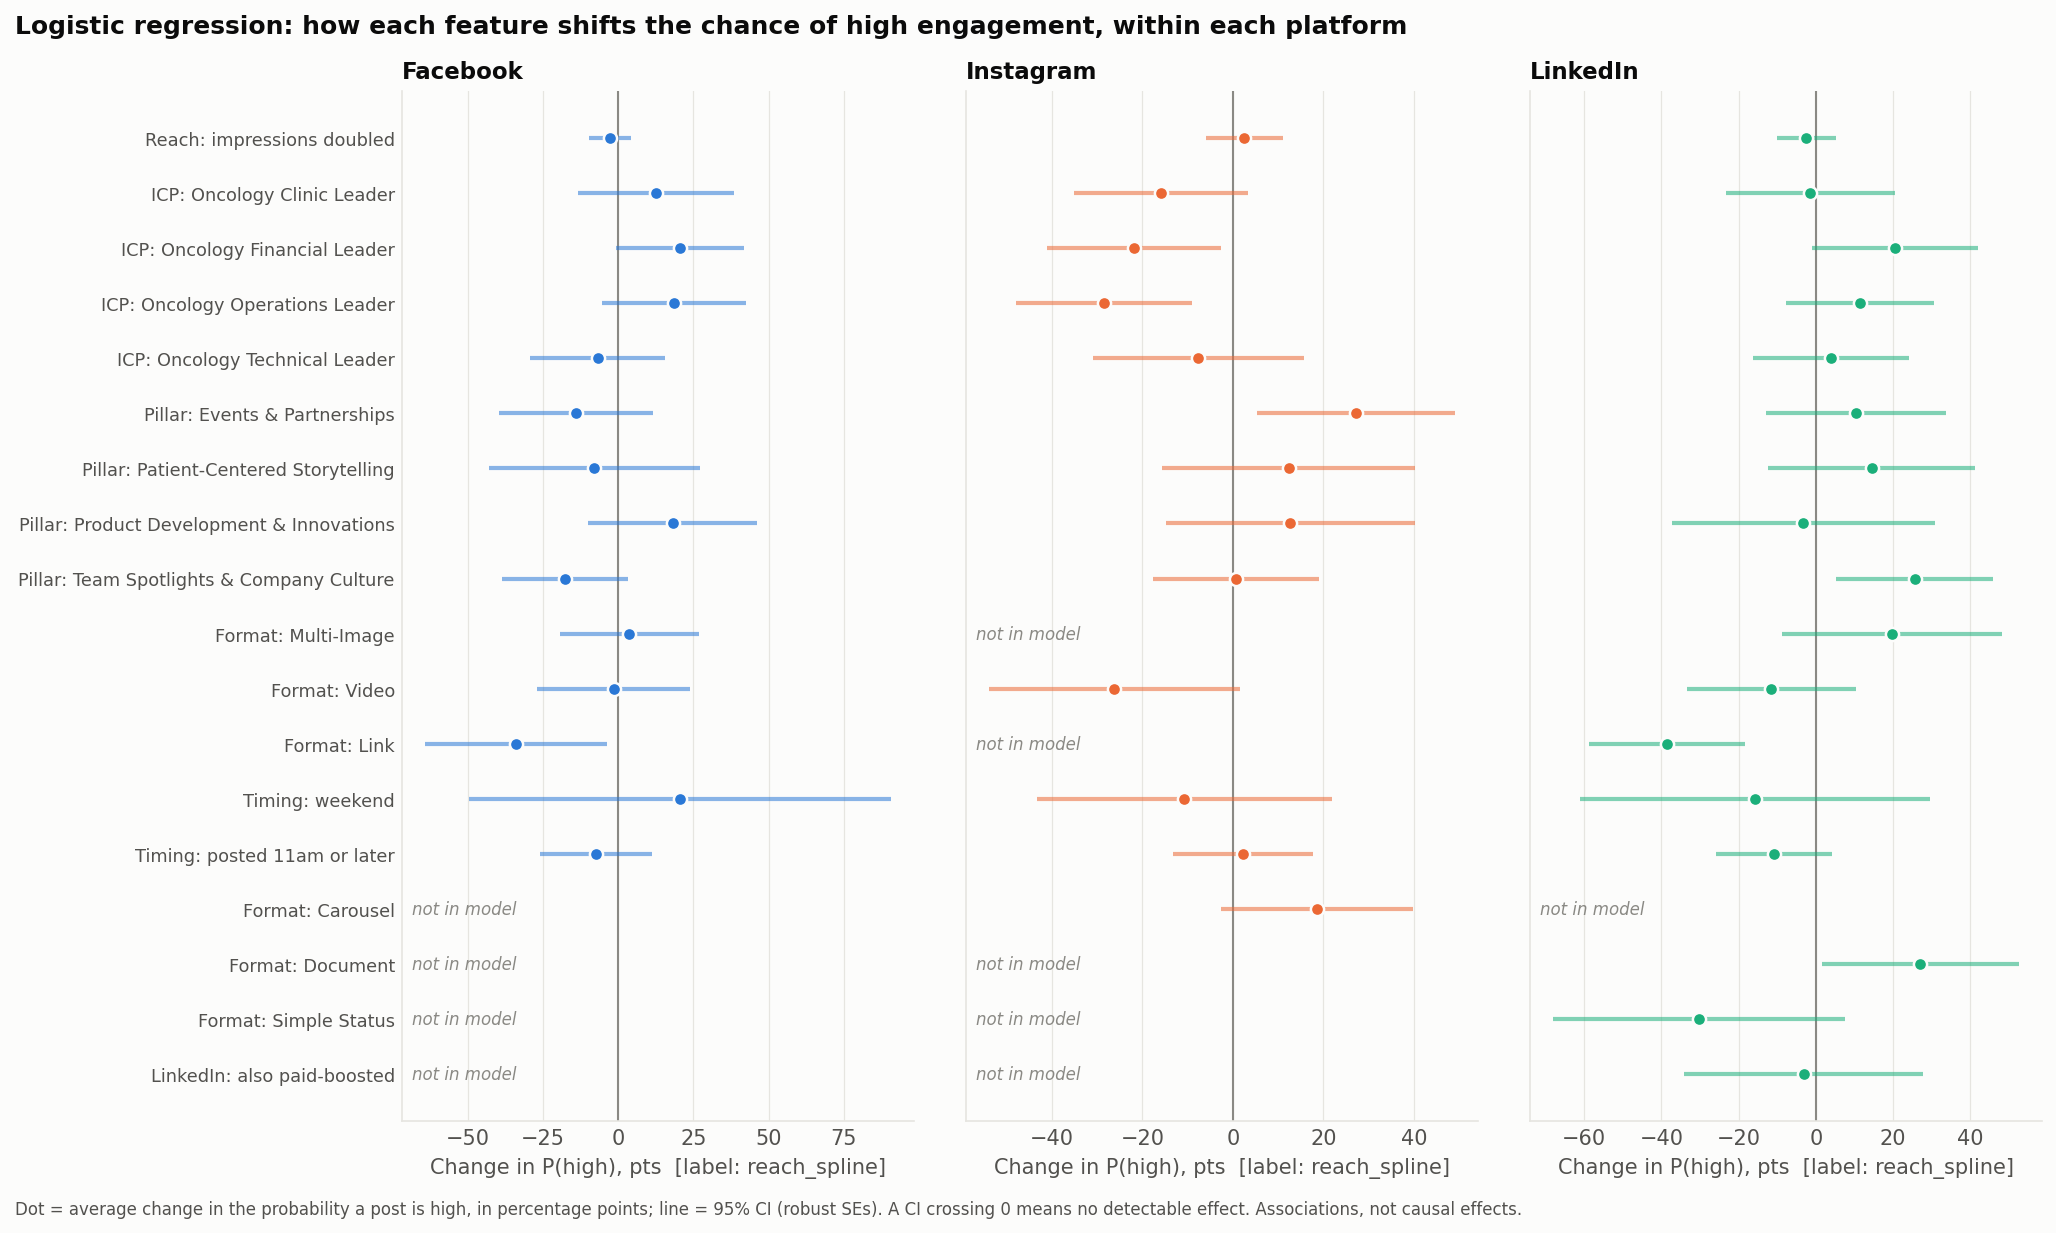

platform,feature,odds_ratio,or_ci_lo,or_ci_hi,p_value,ame_pts,posts_with_feature
Instagram,ICP: Oncology Operations Leader,0.24,0.08,0.74,0.01,-28.49,87.00
Instagram,Pillar: Events & Partnerships,3.80,1.13,12.77,0.03,27.11,23.00
LinkedIn,Pillar: Team Spotlights & Company Culture,3.78,1.19,12.07,0.02,25.63,39.00
LinkedIn,Format: Link,0.11,0.02,0.59,0.01,-38.53,18.00
pooled,Format: Link,0.16,0.05,0.51,0.00,-34.64,26.00
pooled,Format: Carousel,2.88,1.14,7.27,0.02,23.54,28.00


,platform,n_posts,share_high,pseudo_r2,llr_pvalue,converged
0,Facebook,123,0.472,0.107,0.195,True
1,Instagram,130,0.469,0.157,0.008,True
2,LinkedIn,137,0.474,0.179,0.009,True
3,pooled,390,0.472,0.062,0.030,True


In [6]:
fig(CLS, "logistic_effects_by_platform.png")
eff = read(CLS, "logistic_effects.csv").query("feature != 'const'")
sig = eff[(eff["or_ci_lo"] > 1) | (eff["or_ci_hi"] < 1)].assign(feature=lambda d: d["feature"].map(lab))
show(sig[["platform", "feature", "odds_ratio", "or_ci_lo", "or_ci_hi", "p_value", "ame_pts", "posts_with_feature"]],
     "Effects whose 95% CI excludes 1 (unadjusted; see section 6 for multiple testing)")
fs = read(CLS, "logistic_fit_stats.csv")
display(fs[["platform", "n_posts", "share_high", "pseudo_r2", "llr_pvalue", "converged"]])

### 4.2 Feature groups: joint Wald tests
Does a whole group (e.g. all format dummies together) matter? One test per group avoids testing each dummy
separately.

In [7]:
gt = read(CLS, "logistic_group_tests.csv")
display(gt.pivot(index="group", columns="platform", values="p_value")[PLATFORMS].rename_axis("Wald p-value"))

platform,Facebook,Instagram,LinkedIn,pooled
Wald p-value,,,,
Content pillar,0.174,0.252,0.227,0.848
Format,0.495,0.062,0.006,0.000
ICP segment,0.129,0.098,0.337,0.772
Paid boost,NaN,NaN,0.842,0.842
Platform,NaN,NaN,NaN,0.457
Reach (impressions),0.474,0.562,0.532,0.615
Timing,0.670,0.774,0.292,0.465


### 4.3 Bootstrap stability (500 refits of the lasso logistic)
Effects kept in ≥ 80% of refits with ≥ 95% sign agreement.

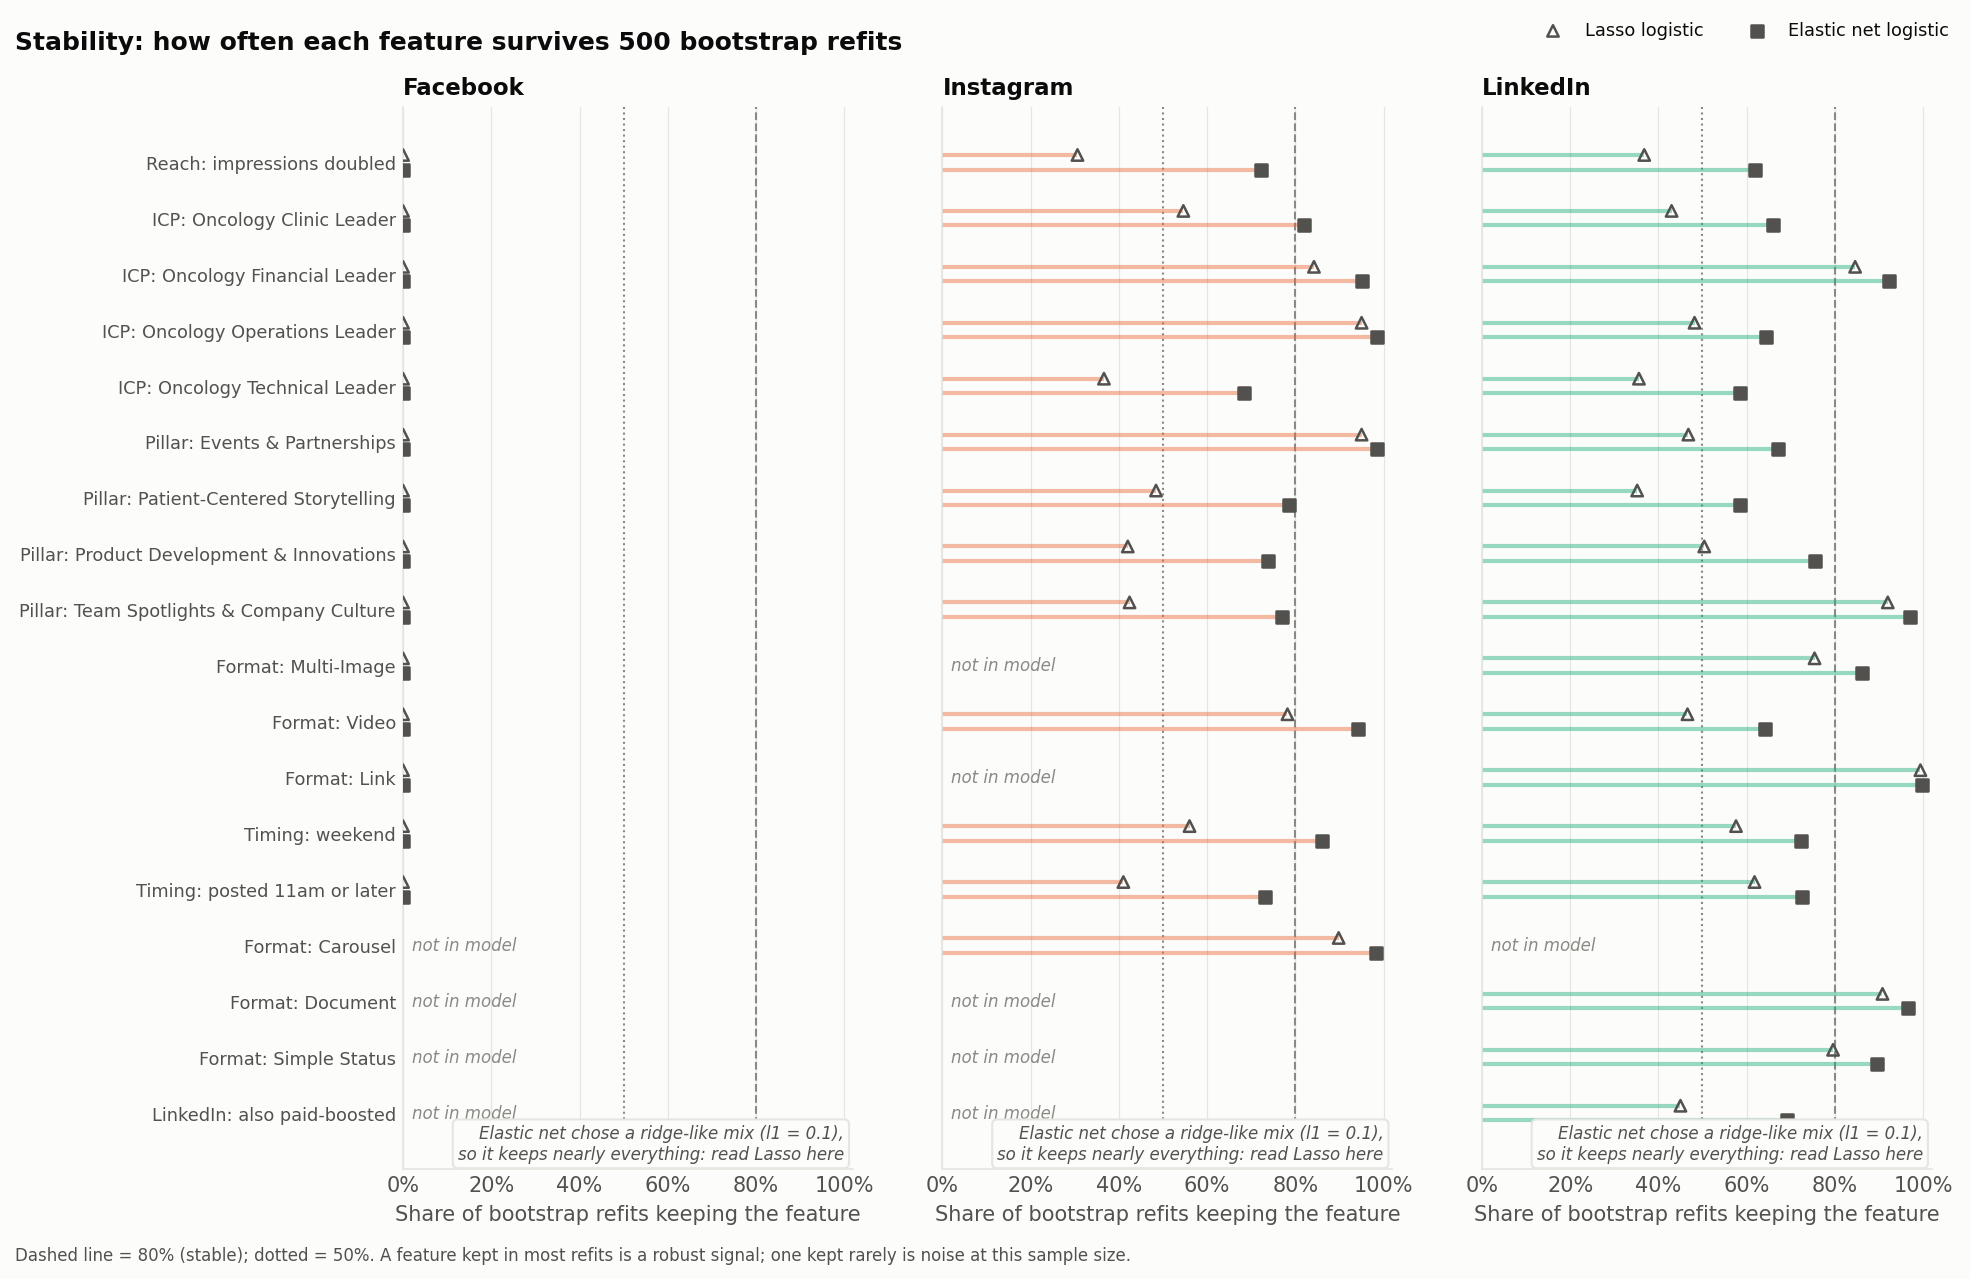

platform,feature,selection_freq,sign_agreement,or_lo,or_median,or_hi
Instagram,ICP: Oncology Financial Leader,0.84,1.00,0.23,0.61,1.00
Instagram,ICP: Oncology Operations Leader,0.95,1.00,0.21,0.47,1.00
Instagram,Pillar: Events & Partnerships,0.95,1.00,1.00,2.53,7.88
Instagram,Format: Carousel,0.90,1.00,1.00,1.89,4.84
LinkedIn,ICP: Oncology Financial Leader,0.85,1.00,1.00,1.65,4.08
LinkedIn,Pillar: Team Spotlights & Company Culture,0.92,1.00,1.00,1.88,4.37
LinkedIn,Format: Link,0.99,1.00,0.07,0.23,0.67
LinkedIn,Format: Document,0.91,1.00,1.00,2.65,8.75
pooled,Format: Link,0.99,1.00,0.15,0.36,0.78
pooled,Format: Carousel,0.87,1.00,1.00,1.59,3.35


In [8]:
fig(CLS, "stability_by_platform.png")
st = read(CLS, "stability.csv")
stable = st[(st["model"] == "Lasso logistic") & (st["selection_freq"] >= 0.8) & (st["sign_agreement"] >= 0.95)]
show(stable.assign(feature=stable["feature"].map(lab))
     [["platform", "feature", "selection_freq", "sign_agreement", "or_lo", "or_median", "or_hi"]],
     "Stable lasso logistic effects (odds ratio, bootstrap 2.5 / 50 / 97.5%)")

### 4.4 Permutation importance (held-out AUC drop when a group is shuffled)
Ridge logistic and random forest. Near 0 = the model does not rely on the group.

In [9]:
for name, f in [("ridge logistic", "importance.csv"), ("random forest", "importance_forest.csv")]:
    g = read(CLS, f).query("level == 'group'")
    display(g.pivot(index="unit", columns="platform", values="auc_drop_mean")[PLATFORMS]
            .sort_values("pooled", ascending=False).rename_axis(f"AUC drop, {name}"))

platform,Facebook,Instagram,LinkedIn,pooled
"AUC drop, ridge logistic",,,,
Format,0.009,0.037,0.119,0.081
Timing,0.000,-0.008,0.005,0.004
Reach (impressions),0.000,0.001,0.001,-0.000
Platform,NaN,NaN,NaN,-0.001
Content pillar,-0.001,0.018,0.020,-0.003
ICP segment,0.005,0.041,0.003,-0.003
Paid boost,NaN,NaN,-0.005,-0.004


platform,Facebook,Instagram,LinkedIn,pooled
"AUC drop, random forest",,,,
Format,0.013,0.057,0.109,0.085
Platform,NaN,NaN,NaN,0.035
Reach (impressions),0.059,0.013,0.006,0.032
Content pillar,0.037,0.034,0.038,0.026
ICP segment,0.052,0.061,0.015,0.022
Timing,0.027,-0.013,0.001,0.018
Paid boost,NaN,NaN,0.000,0.000


## 5. Robustness: does the label definition matter?
The same models under four labels: the main spline label, the earlier straight-line reach label, and two raw-rate
labels that ignore reach (above the platform median; top third). Best held-out AUC per platform:

In [10]:
best = {}
for name, run in LABEL_RUNS.items():
    s = read(run, "cv_summary.csv").query("model != 'base rate (reference)'")
    idx = s.groupby("platform")["auc_mean"].idxmax()
    best[name] = s.loc[idx].set_index("platform").apply(lambda r: f"{r['auc_mean']:.2f} ({r['model']})", axis=1)
display(pd.DataFrame(best).reindex(PLATFORMS).rename_axis("best AUC (model)"))

key = ["Format: Document", "Format: Link", "Format: Carousel", "Pillar: Team Spotlights & Company Culture",
       "Pillar: Events & Partnerships"]
rows = []
for name, run in LABEL_RUNS.items():
    s = read(run, "stability.csv").query("model == 'Lasso logistic' and feature in @key")
    s = s.assign(cell=np.where((s["selection_freq"] >= 0.8) & (s["sign_agreement"] >= 0.95),
                               s["or_median"].map("{:.2f}".format), "–"), label=name)
    rows.append(s)
rob = pd.concat(rows).pivot_table(index=["platform", "feature"], columns="label", values="cell", aggfunc="first")
display(rob[list(LABEL_RUNS)].rename_axis(None, axis=1)
        .style.set_caption("Lasso odds ratio where stable (≥80% kept, ≥95% sign); – = not stable"))

,reach spline (main),reach line,above median,top third
best AUC (model),,,,
Facebook,0.64 (Random forest),0.66 (Random forest),0.70 (Random forest),0.67 (Random forest)
Instagram,0.67 (Random forest),0.68 (Random forest),0.79 (Random forest),0.79 (Random forest)
LinkedIn,0.66 (Ridge logistic),0.66 (Ridge logistic),0.66 (Ridge logistic),0.64 (Ridge logistic)
pooled,0.64 (Random forest),0.65 (Random forest),0.71 (Random forest),0.72 (Random forest)


- **Instagram's high AUC under raw-rate labels is reach**, not content: shuffling reach costs 0.21–0.25 AUC there.
  With reach removed (spline label), Instagram drops to ≈ 0.66 and the forest leans on content instead.
- **LinkedIn / pooled Document and pooled Link are stable under every label.**

## 6. Evaluation framework
Two outcomes throughout: **rate** (engagement rate, pts) and **rate vs. reach** (rate minus the spline-expected rate
for the post's reach — the continuous version of the main label). BH = Benjamini–Hochberg false-discovery-rate
adjustment; Holm = family-wise error control.

### 6.1 Do pillars or ICP segments differ? (item 4)
One-way tests on posts with a single tag (groups with < 5 posts dropped), plus a post-clustered Wald test on all
posts (multi-tag posts repeated once per tag). ω² = share of variance explained, corrected for chance.

In [11]:
g = read(EV, "group_tests.csv")
show(g[["platform", "factor", "outcome", "n_posts", "n_groups", "anova_p", "welch_p", "kruskal_p", "clustered_p",
        "omega2", "anova_p_bh", "kruskal_p_bh", "clustered_p_bh"]], precision=3)
tk = read(EV, "tukey_pairs.csv")
print(f"Tukey HSD pairs tested: {len(tk)}; pairs that differ: {int(tk['reject'].sum())}")
print(f"Smallest BH-adjusted p: {g.filter(like='_p_bh').min().min():.2f}; largest ω²: {g['omega2'].max():.3f}")

platform,factor,outcome,n_posts,n_groups,anova_p,welch_p,kruskal_p,clustered_p,omega2,anova_p_bh,kruskal_p_bh,clustered_p_bh
Facebook,Content pillar,rate,119,5,0.249,0.187,0.381,0.101,0.012,0.498,0.684,0.304
Facebook,Content pillar,rate_vs_reach,119,5,0.059,0.105,0.051,0.037,0.043,0.178,0.201,0.225
Facebook,ICP segment,rate,87,4,0.560,0.353,0.570,0.228,-0.011,0.560,0.684,0.342
Facebook,ICP segment,rate_vs_reach,87,4,0.059,0.060,0.121,0.423,0.052,0.178,0.241,0.633
Instagram,Content pillar,rate,125,5,0.205,0.205,0.100,0.185,0.016,0.498,0.600,0.342
Instagram,Content pillar,rate_vs_reach,125,5,0.258,0.325,0.067,0.261,0.011,0.309,0.201,0.523
Instagram,ICP segment,rate,90,4,0.213,0.212,0.249,0.674,0.017,0.498,0.684,0.674
Instagram,ICP segment,rate_vs_reach,90,4,0.240,0.294,0.210,0.528,0.014,0.309,0.315,0.633
LinkedIn,Content pillar,rate,133,5,0.456,0.534,0.784,0.497,-0.002,0.547,0.784,0.597
LinkedIn,Content pillar,rate_vs_reach,133,5,0.781,0.735,0.560,0.650,-0.017,0.781,0.560,0.650


Tukey HSD pairs tested: 96; pairs that differ: 0
Smallest BH-adjusted p: 0.18; largest ω²: 0.052


**No pillar or ICP segment differs from another on any platform** after correction, and they explain ≤ 5% of
variance. This agrees with notebook 02 and with every classification model.

### 6.2 Are the standard errors trustworthy? (item 5)
Naive (constant-variance) vs. HC3 (robust) vs. clustered SEs. In the pooled model, the cluster is the content item
posted on several platforms; in the tag models, the post (repeated once per tag).

In [12]:
cs = read(EV, "clustered_se.csv").assign(ratio_clustered_to_hc3=lambda d: d["se_clustered"] / d["se_hc3"])
print(cs.groupby("model")[["ratio_clustered_to_naive", "ratio_clustered_to_hc3"]].agg(["min", "median", "max"])
      .round(2).to_string())
pooled = cs[cs["model"].str.startswith("pooled")].sort_values("ratio_clustered_to_naive", ascending=False).head(6)
show(pooled[["term", "coef", "se_naive", "se_hc3", "se_clustered", "p_naive", "p_clustered"]], precision=3)

                                                                                      ratio_clustered_to_naive              ratio_clustered_to_hc3             
                                                                                                           min median   max                    min median   max
model                                                                                                                                                          
Content pillar dummies, post × tag rows (ref: Thought Leadership & Industry Insights)                    0.670  0.960 1.390                  0.910  0.980 1.000
ICP segment dummies, post × tag rows (ref: Oncology Operations Leader)                                   0.640  0.820 1.380                  0.760  0.910 0.970
pooled OLS, one row per post (clustered by content piece)                                                0.510  0.870 1.800                  0.690  0.900 1.060


term,coef,se_naive,se_hc3,se_clustered,p_naive,p_clustered
log2_impressions,-2.131,0.370,0.714,0.665,0.000,0.001
Format: Document,9.268,2.640,4.990,4.732,0.001,0.050
Platform: LinkedIn,3.454,1.841,3.159,2.939,0.061,0.240
Format: Link,-4.726,1.862,2.479,2.320,0.012,0.042
Format: Carousel,2.850,1.836,2.038,2.001,0.122,0.154
Platform: Instagram,5.076,1.201,1.299,1.279,0.000,0.000


Clustered SEs are within ~0.7–1.06× of HC3 everywhere: **repeated posts do not distort uncertainty**. Naive SEs are
too small by up to 1.8× (reach, Document) because of unequal variance, so the project's robust SEs are the right
choice and naive ones should not be reported.

### 6.3 How big are the effects? (item 7)
Hedges' g (standardized mean difference, small-sample corrected) with 95% CI, posts with a feature vs. the
comparison group (formats vs. Image; others vs. posts without it). Rough guide: 0.2 small, 0.5 medium, 0.8 large.

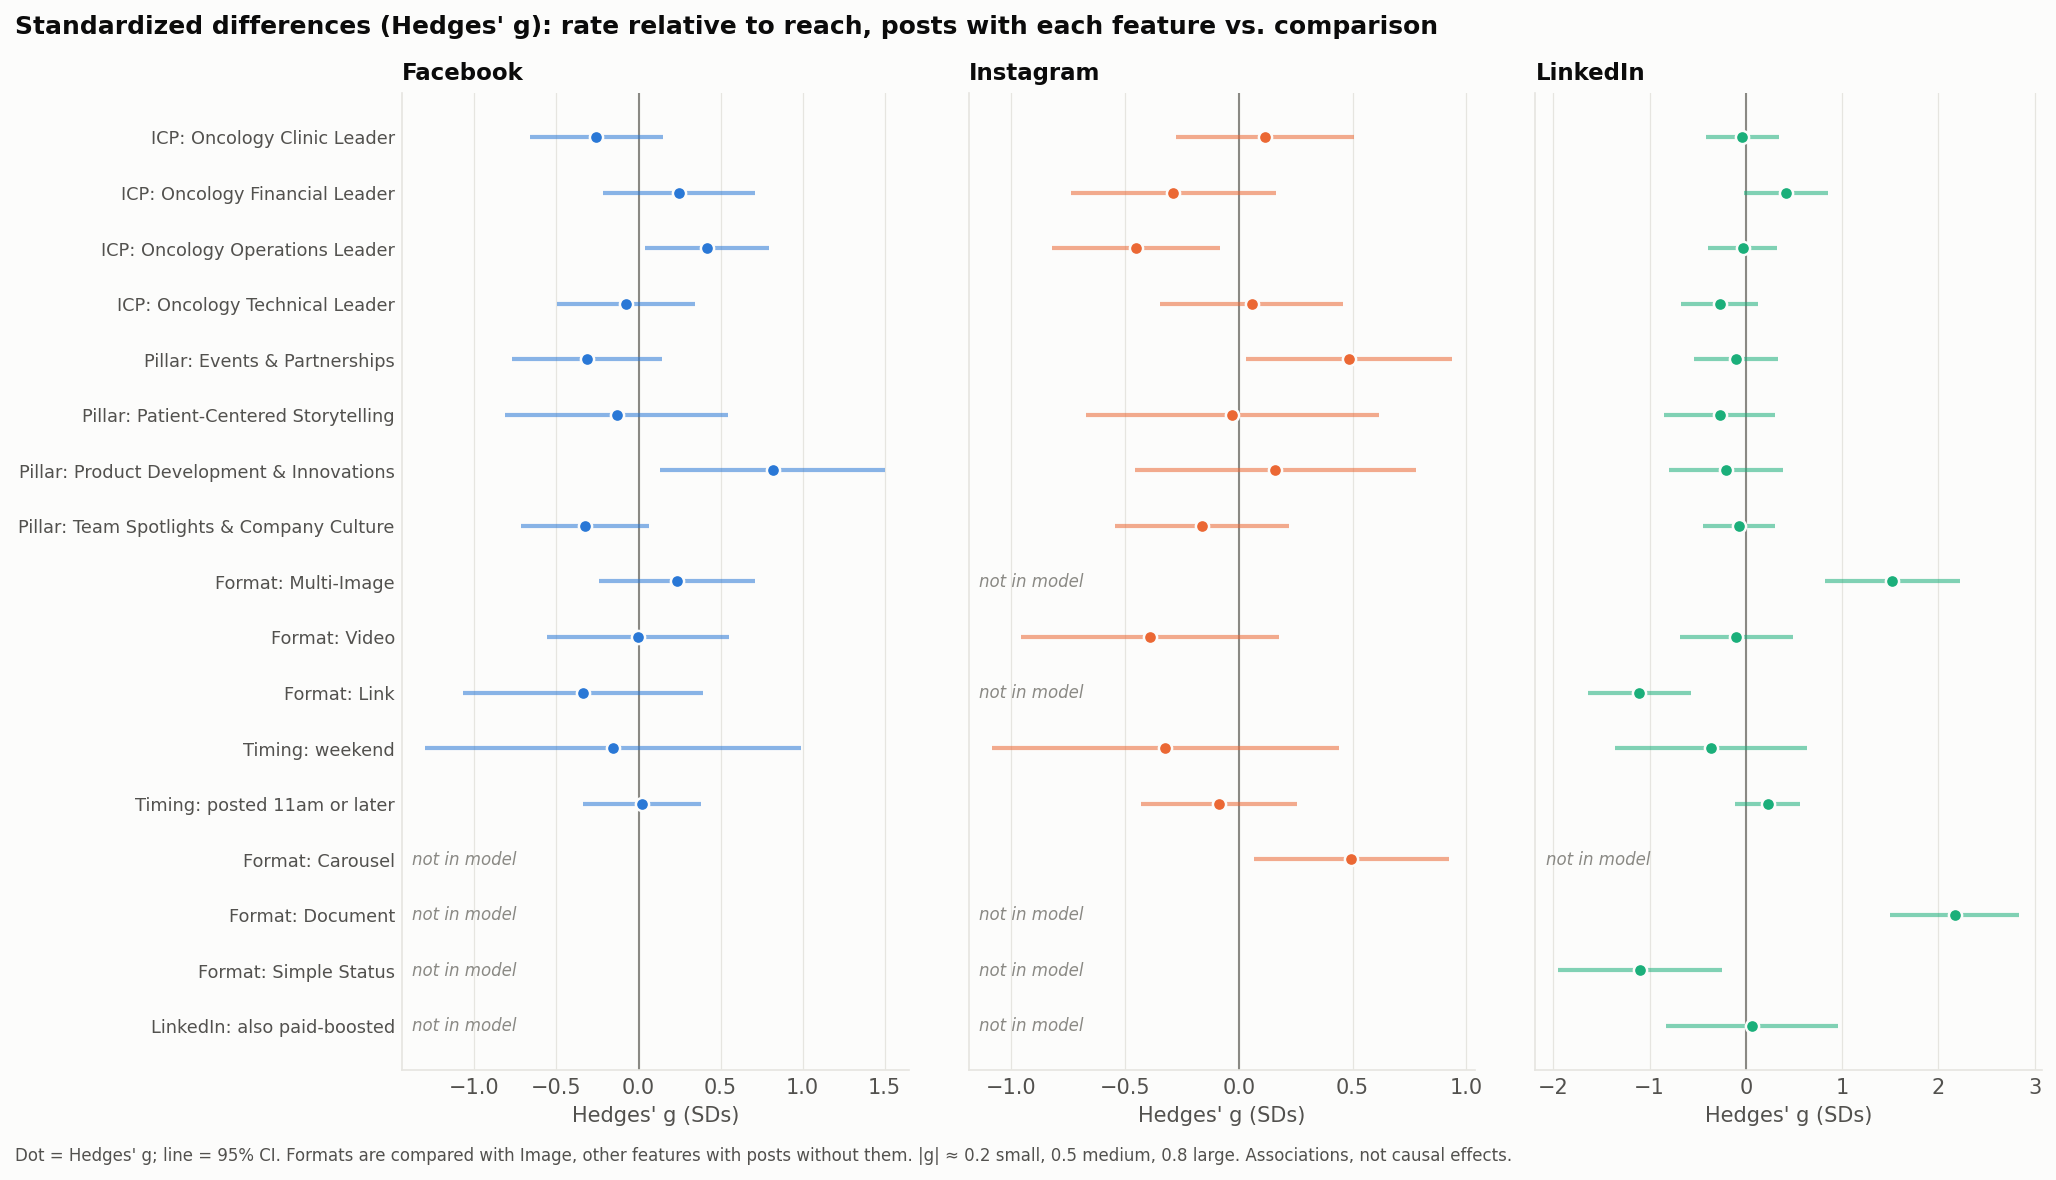

platform,feature,compared_with,n_with,n_compared,diff_pts,hedges_g,ci_lo,ci_hi
Facebook,Pillar: Product Development & Innovations,posts without it,9,114,7.38,0.82,0.13,1.50
Facebook,ICP: Oncology Operations Leader,posts without it,82,41,3.76,0.41,0.04,0.79
Instagram,Format: Carousel,Image,28,88,2.63,0.49,0.06,0.92
Instagram,Pillar: Events & Partnerships,posts without it,23,107,2.49,0.48,0.03,0.94
Instagram,ICP: Oncology Operations Leader,posts without it,87,43,-2.32,-0.45,-0.82,-0.08
LinkedIn,Format: Document,Image,13,77,14.11,2.17,1.50,2.84
LinkedIn,Format: Multi-Image,Image,10,77,5.23,1.52,0.83,2.22
LinkedIn,Format: Simple Status,Image,6,77,-3.17,-1.10,-1.95,-0.25
LinkedIn,Format: Link,Image,18,77,-2.95,-1.11,-1.64,-0.57
pooled,Format: Document,Image,13,243,13.77,1.87,1.29,2.45


outcome                        rate                           rate_vs_reach                          
platform                   Facebook Instagram LinkedIn pooled      Facebook Instagram LinkedIn pooled
partial R² (in-sample OLS)                                                                           
Content pillar                0.027     0.020    0.019  0.001         0.077     0.037    0.002  0.010
Format                        0.085     0.054    0.192  0.092         0.065     0.050    0.364  0.146
ICP segment                   0.033     0.064    0.002  0.002         0.051     0.058    0.016  0.003
Paid boost                      NaN       NaN    0.005  0.002           NaN       NaN    0.002  0.001
Platform                        NaN       NaN      NaN  0.046           NaN       NaN      NaN  0.002
Reach (impressions)           0.024     0.422    0.049  0.082         0.031     0.001    0.014  0.000
Timing                        0.013     0.002    0.001  0.001         0.003     0.006    0.001  0.002

In [13]:
fig(EV, "hedges_g_by_platform.png")
d = read(EV, "cohens_d.csv").query("outcome == 'rate_vs_reach'")
big = d[(d["ci_lo"] > 0) | (d["ci_hi"] < 0)].sort_values(["platform", "hedges_g"], ascending=[True, False])
show(big[["platform", "feature", "compared_with", "n_with", "n_compared", "diff_pts", "hedges_g", "ci_lo", "ci_hi"]],
     "Rate vs. reach: effects whose 95% CI excludes 0 (unadjusted)")
pr = read(EV, "partial_r2.csv").query("level == 'group'")
display(pr.pivot_table(index="unit", columns=["outcome", "platform"], values="partial_r2")
        .reindex(columns=PLATFORMS, level=1).rename_axis("partial R² (in-sample OLS)"))

- **LinkedIn Document: g ≈ 2.2** (CI 1.5–2.8), about +14 pts over Image after reach — a very large effect.
  Format explains **36%** of LinkedIn's remaining variance in rate vs. reach; no other LinkedIn group exceeds 5%.
- Instagram content effects (Carousel, Events & Partnerships, Operations Leader) are medium (|g| ≈ 0.45–0.5),
  with CIs close to 0.
- Instagram reach explains 42% of raw rate and ≈ 0 of rate vs. reach: the spline removes it.

### 6.4 Ranked drivers with multiple-testing correction (item 3)
Every modelled feature, with regression and logistic p-values adjusted within platform (Holm and BH), lasso
stability in both tasks, permutation importance and Hedges' g. `evidence` lists the independent lines of support
(BH p < 0.05, stable lasso). Ranked by the best BH-adjusted p.

In [14]:
dr = read(EV, "driver_ranking.csv")
cols = ["platform", "rank", "feature", "coef_pts", "p_reg", "p_reg_bh", "odds_ratio", "p_logit", "p_logit_bh",
        "hedges_g_vs_reach", "evidence"]
show(dr[dr["rank"] <= 5][cols].assign(feature=lambda x: x["feature"].map(lab)), "Top 5 per platform", precision=3)
print("Surviving BH (< 0.05):")
print(dr[dr["best_p_bh"] < 0.05][["platform", "feature", "best_p_bh"]].to_string(index=False))
li = dr.query("platform == 'LinkedIn' and feature == 'Format: Document'").iloc[0]
print(f"\nLinkedIn Document: regression p {li['p_reg']:.3f} → BH {li['p_reg_bh']:.2f}; "
      f"logistic p {li['p_logit']:.3f} → BH {li['p_logit_bh']:.2f}")

platform,rank,feature,coef_pts,p_reg,p_reg_bh,odds_ratio,p_logit,p_logit_bh,hedges_g_vs_reach,evidence
Facebook,1,Format: Link,-10.967,0.041,0.574,0.152,0.142,0.505,-0.339,–
Facebook,2,ICP: Oncology Financial Leader,3.675,0.216,0.725,2.614,0.075,0.505,0.249,–
Facebook,3,Pillar: Team Spotlights & Company Culture,-2.724,0.181,0.725,0.441,0.113,0.505,-0.328,–
Facebook,4,ICP: Oncology Operations Leader,2.146,0.389,0.725,2.348,0.144,0.505,0.415,–
Facebook,5,Pillar: Product Development & Innovations,2.415,0.621,0.790,2.351,0.230,0.644,0.819,–
Instagram,1,Reach: impressions doubled,-6.219,0.000,0.000,1.136,0.562,0.664,–,regression p (BH); stable lasso (reg)
Instagram,2,ICP: Oncology Operations Leader,-1.136,0.508,0.800,0.244,0.013,0.169,-0.452,stable lasso (logit)
Instagram,3,Pillar: Events & Partnerships,1.817,0.189,0.615,3.805,0.031,0.198,0.483,stable lasso (logit)
Instagram,4,ICP: Oncology Financial Leader,-2.417,0.062,0.267,0.316,0.055,0.236,-0.288,stable lasso (reg); stable lasso (logit)
Instagram,5,Format: Carousel,3.574,0.058,0.267,2.463,0.098,0.305,0.495,stable lasso (reg); stable lasso (logit)


Surviving BH (< 0.05):
 platform               feature  best_p_bh
Instagram      log2_impressions      0.000
   pooled   Platform: Instagram      0.001
   pooled      log2_impressions      0.013
   pooled         Format: Video      0.014
   pooled Format: Simple Status      0.014
   pooled          Format: Link      0.035

LinkedIn Document: regression p 0.030 → BH 0.51; logistic p 0.061 → BH 0.35


**Single-feature p-values mostly do not survive correction**: within a platform only Instagram reach (regression)
does; LinkedIn Document goes from p 0.03 to 0.51 (BH) because 13 Document posts give a wide CI despite a large
effect. **The group-level test does survive:** LinkedIn Format p 0.006 → 0.037 and pooled Format < 0.001 → 0.001
(BH across feature groups). So the defensible claim is *format matters*; individual formats are reported with
effect sizes, CIs and stability, as exploratory.

## 7. Conclusions

**Robust** (survives multiple testing at the group level, large effect sizes, stable across labels and knots):
1. **Format matters on LinkedIn and pooled.** Joint Wald test survives BH (LinkedIn p = 0.037, pooled 0.001).
   **LinkedIn Document** is the strongest single lever: lasso odds ratio ≈ 2.7 of being high (2.7–4.1 across labels), ≈ +14 pts over Image
   after reach, g ≈ 2.2, stable in every bootstrap, label and knot check. **Link** posts do worse (LinkedIn OR ≈ 0.23;
   pooled Link survives BH alone). Caveat from notebook 02: all 13 Document posts ran Jul–Sep 2026.
2. **Reach shapes raw rates; the spline label removes it.** Instagram reach explains 42% of raw-rate variance; once
   removed, models must rely on content, and Instagram/Facebook AUC is ≈ 0.60–0.67.
3. **Pillar and ICP segment show no detectable differences** (item 4: no BH-significant test, no Tukey pair,
   ω² ≤ 0.05), consistent with notebook 02.

**Suggestive** (medium effects, CIs near 0, knot-sensitive): Instagram Carousel (OR ≈ 1.9), Events & Partnerships
(≈ 2.5), Operations / Financial Leader (≈ 0.5–0.6); LinkedIn Team Spotlights (≈ 1.9, stable but not BH-significant);
LinkedIn Multi-Image (g ≈ 1.5).

**Not predictable / no signal:** Facebook has no stable effect at 4 or 5 knots; timing and boost show nothing.

**Method notes:** use robust or clustered SEs (naive SEs are up to 1.8× too small); compare models by AUC with its
± 0.10 spread, not by small mean differences; per-feature p-values need correction before being claimed.

**Implications for Stage 2 (recommendations):** score planned posts on format and expected reach; present
pillar / segment as strategic choices that the data does not show changing engagement; recommend more LinkedIn
Documents, spread across months, to separate format from timing.

## 8. Reproduce
From the repo root:
```bash
python -m pytest modeling/tests -q                                         # 160 tests
python -m modeling.run_regression --tag <name>                             # regression (~1 min)
python -m modeling.run_classification --tag <name>                         # main label from config (~6 min)
python -m modeling.run_classification --tag <name> --label above_median    # alternative labels
python -m modeling.run_evaluation --tag <name>                             # items 3–7; reads evaluation.sources
```
Same master + same config + same code → identical CSVs. `modeling/config.yaml` sets `main_label` and the
`evaluation.sources` runs.